
# Ensemble Construction and Evaluation

## Objective
Investigate whether combining optimized regression models improves CO₂ uptake prediction compared with individual tuned models.

## Ensemble Strategies
1. Simple averaging ensemble
2. Validation-optimized weighted ensemble
3. Entropy-TOPSIS-based model weighting

## Evaluation
Compare individual tuned models and ensemble predictions using MAE, RMSE, and R² on the existing validation set.

## Data Integrity
- Reuse the fixed train/validation/test assignments.
- Load models fitted on the training set only.
- Use validation predictions for ensemble comparison and weight selection.
- Keep the test set untouched until final evaluation.



In [2]:

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=FutureWarning)

current_dir = Path.cwd()
possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "data" / "Processed_527_datapoints.csv").exists()
        and (path / "artifacts" / "feature_config.json").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found.")

DATA_PATH = PROJECT_ROOT / "data" / "Processed_527_datapoints.csv"
SPLIT_PATH = PROJECT_ROOT / "artifacts" / "splits" / "split_assignments.csv"
FEATURE_CONFIG_PATH = PROJECT_ROOT / "artifacts" / "feature_config.json"
TUNED_MODEL_DIR = PROJECT_ROOT / "artifacts" / "tuned_models"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Tuned model directory:", TUNED_MODEL_DIR)


Project root: /Users/divyakandlakuti/Desktop/interpretable-co2-adsorption-ml
Tuned model directory: /Users/divyakandlakuti/Desktop/interpretable-co2-adsorption-ml/artifacts/tuned_models


In [3]:

df = pd.read_csv(DATA_PATH)
split_assignments = pd.read_csv(SPLIT_PATH)

with open(FEATURE_CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

TARGET_COLUMN = feature_config["target"]
FEATURE_COLUMNS = feature_config["features"]

df = df.drop_duplicates().reset_index(drop=True)

if "row_id" not in df.columns:
    df.insert(0, "row_id", np.arange(len(df)))

data = df.merge(
    split_assignments[["row_id", "split"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

if len(data) != len(split_assignments):
    raise ValueError(
        "Dataset rows do not match the saved split. "
        "Stop and inspect row_id alignment."
    )

val_df = data.loc[data["split"] == "validation"].copy()
X_val = val_df[FEATURE_COLUMNS]
y_val = val_df[TARGET_COLUMN].to_numpy()

test_df = data.loc[data["split"] == "test"].copy()

print("Validation rows:", len(val_df))
print("Reserved test rows:", len(test_df))
print("Target:", TARGET_COLUMN)


Validation rows: 84
Reserved test rows: 106
Target: CO2 uptake (mmol/g)


In [4]:

MODEL_FILES = {
    "Random Forest": "tuned_random_forest.joblib",
    "Extra Trees": "tuned_extra_trees.joblib",
    "Gradient Boosting": "tuned_gradient_boosting.joblib",
    "XGBoost": "tuned_xgboost.joblib",
    "LightGBM": "tuned_lightgbm.joblib",
    "CatBoost": "tuned_catboost.joblib",
}

tuned_pipelines = {}

for model_name, filename in MODEL_FILES.items():
    model_path = TUNED_MODEL_DIR / filename

    if not model_path.exists():
        raise FileNotFoundError(
            f"Missing tuned model: {model_path}. "
            "Run Notebook 06 completely first."
        )

    tuned_pipelines[model_name] = joblib.load(model_path)

print("Successfully loaded", len(tuned_pipelines), "tuned pipelines.")


Successfully loaded 6 tuned pipelines.


In [5]:

validation_predictions = {}

for model_name, pipeline in tuned_pipelines.items():
    predictions = pipeline.predict(X_val)

    if not np.isfinite(predictions).all():
        raise ValueError(
            f"{model_name} produced non-finite validation predictions."
        )

    validation_predictions[model_name] = predictions

prediction_df = pd.DataFrame({
    "row_id": val_df["row_id"].to_numpy(),
    "Actual_CO2_uptake": y_val,
})

for model_name, predictions in validation_predictions.items():
    prediction_df[model_name] = predictions

print("Validation predictions generated for all six models.")
display(prediction_df.head())


Validation predictions generated for all six models.


,row_id,Actual_CO2_uptake,Random Forest,Extra Trees,Gradient Boosting,XGBoost,LightGBM,CatBoost
0,1,2.586364,2.859121,2.779716,2.560742,2.886624,3.155556,3.190611
1,19,3.460000,3.540175,3.688041,3.566114,3.693057,3.453436,3.377408
2,23,2.900000,2.618640,2.545638,2.486684,2.817947,2.938026,2.578469
3,26,3.650000,2.947020,3.035262,2.936229,2.836550,3.229929,3.449132
4,27,1.770000,1.435623,1.550687,1.398885,1.498994,1.122972,1.189604


In [6]:

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

individual_results = []

for model_name, predictions in validation_predictions.items():
    metrics = calculate_metrics(y_val, predictions)

    individual_results.append({
        "Model": model_name,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "R2": metrics["R2"],
    })

individual_results_df = (
    pd.DataFrame(individual_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(individual_results_df.round(4))


,Model,MAE,RMSE,R2
0,CatBoost,0.3909,0.5898,0.8466
1,LightGBM,0.3953,0.5984,0.8421
2,XGBoost,0.4051,0.6154,0.8330
3,Gradient Boosting,0.4093,0.6641,0.8055
4,Extra Trees,0.4435,0.6655,0.8047
5,Random Forest,0.4582,0.6771,0.7978


In [7]:

prediction_matrix = np.column_stack([
    validation_predictions[name]
    for name in validation_predictions
])

model_names = list(validation_predictions.keys())

simple_average_predictions = prediction_matrix.mean(axis=1)

simple_average_metrics = calculate_metrics(
    y_val,
    simple_average_predictions,
)

print("Simple Averaging Ensemble")
for metric, value in simple_average_metrics.items():
    print(f"{metric}: {value:.4f}")


Simple Averaging Ensemble
MAE: 0.3869
RMSE: 0.6086
R2: 0.8366


In [8]:

n_models = prediction_matrix.shape[1]

def ensemble_objective(weights):
    combined = prediction_matrix @ weights
    return np.sqrt(mean_squared_error(y_val, combined))

initial_weights = np.full(n_models, 1 / n_models)

optimization = minimize(
    ensemble_objective,
    initial_weights,
    method="SLSQP",
    bounds=[(0.0, 1.0)] * n_models,
    constraints=[
        {"type": "eq", "fun": lambda weights: np.sum(weights) - 1.0}
    ],
    options={"maxiter": 2000, "ftol": 1e-10},
)

if not optimization.success:
    raise RuntimeError(
        f"Weight optimization failed: {optimization.message}"
    )

weighted_ensemble_weights = optimization.x
weighted_ensemble_weights = np.clip(weighted_ensemble_weights, 0, 1)
weighted_ensemble_weights /= weighted_ensemble_weights.sum()

weighted_ensemble_predictions = (
    prediction_matrix @ weighted_ensemble_weights
)

weighted_ensemble_metrics = calculate_metrics(
    y_val,
    weighted_ensemble_predictions,
)

print("Validation-Optimized Weighted Ensemble")
for name, weight in zip(model_names, weighted_ensemble_weights):
    print(f"{name}: {weight:.4f}")

print("\nMetrics")
for metric, value in weighted_ensemble_metrics.items():
    print(f"{metric}: {value:.4f}")



Validation-Optimized Weighted Ensemble
Random Forest: 0.0000
Extra Trees: 0.0000
Gradient Boosting: 0.0000
XGBoost: 0.1770
LightGBM: 0.2766
CatBoost: 0.5464

Metrics
MAE: 0.3741
RMSE: 0.5759
R2: 0.8537


In [9]:

from scipy.spatial.distance import cdist

criteria_df = individual_results_df[["MAE", "RMSE", "R2"]].copy()

# Convert all criteria to cost criteria: smaller is better.
decision_matrix = np.column_stack([
    criteria_df["MAE"].to_numpy(),
    criteria_df["RMSE"].to_numpy(),
    1.0 - criteria_df["R2"].to_numpy(),
])

# Min-max normalization for cost criteria.
column_min = decision_matrix.min(axis=0)
column_max = decision_matrix.max(axis=0)
column_range = column_max - column_min

normalized_costs = np.divide(
    decision_matrix - column_min,
    column_range,
    out=np.zeros_like(decision_matrix, dtype=float),
    where=column_range != 0,
)

# Entropy weights calculated from non-negative proportions.
shifted = normalized_costs + 1e-12
proportions = shifted / shifted.sum(axis=0, keepdims=True)

n_alternatives = proportions.shape[0]
entropy = -np.sum(
    proportions * np.log(proportions),
    axis=0,
) / np.log(n_alternatives)

diversity = 1.0 - entropy

if diversity.sum() <= 1e-12:
    criterion_weights = np.full(decision_matrix.shape[1], 1 / 3)
else:
    criterion_weights = diversity / diversity.sum()

# TOPSIS works on a normalized benefit-oriented matrix.
# Higher normalized benefit means lower error.
benefit_matrix = 1.0 - normalized_costs

denominators = np.sqrt((benefit_matrix ** 2).sum(axis=0))
weighted_normalized = benefit_matrix / np.where(
    denominators == 0, 1.0, denominators
)
weighted_normalized *= criterion_weights

ideal_best = weighted_normalized.max(axis=0)
ideal_worst = weighted_normalized.min(axis=0)

distance_best = np.linalg.norm(
    weighted_normalized - ideal_best, axis=1
)
distance_worst = np.linalg.norm(
    weighted_normalized - ideal_worst, axis=1
)

closeness = distance_worst / (
    distance_best + distance_worst + 1e-12
)

entropy_topsis_weights = closeness / closeness.sum()

entropy_topsis_weight_table = pd.DataFrame({
    "Model": individual_results_df["Model"],
    "TOPSIS_Closeness": closeness,
    "Ensemble_Weight": entropy_topsis_weights,
})

print("Entropy criterion weights:")
print({
    "MAE": round(float(criterion_weights[0]), 4),
    "RMSE": round(float(criterion_weights[1]), 4),
    "1_minus_R2": round(float(criterion_weights[2]), 4),
})

display(entropy_topsis_weight_table.round(4))

# Reorder the weights to match prediction_matrix/model_names.
topsis_weight_by_model = dict(zip(
    entropy_topsis_weight_table["Model"],
    entropy_topsis_weight_table["Ensemble_Weight"],
))

entropy_topsis_weights_ordered = np.array([
    topsis_weight_by_model[name] for name in model_names
])

entropy_topsis_predictions = (
    prediction_matrix @ entropy_topsis_weights_ordered
)

entropy_topsis_metrics = calculate_metrics(
    y_val,
    entropy_topsis_predictions,
)

print("\nEntropy-TOPSIS Ensemble Metrics")
for metric, value in entropy_topsis_metrics.items():
    print(f"{metric}: {value:.4f}")


Entropy criterion weights:
{'MAE': 0.3888, 'RMSE': 0.3025, '1_minus_R2': 0.3087}


,Model,TOPSIS_Closeness,Ensemble_Weight
0,CatBoost,1.0000,0.3093
1,LightGBM,0.9152,0.2831
2,XGBoost,0.7410,0.2292
3,Gradient Boosting,0.4048,0.1252
4,Extra Trees,0.1720,0.0532
5,Random Forest,0.0000,0.0000



Entropy-TOPSIS Ensemble Metrics
MAE: 0.3755
RMSE: 0.5867
R2: 0.8482


In [10]:

ensemble_results = individual_results.copy()

ensemble_results.extend([
    {
        "Model": "Simple Averaging Ensemble",
        **simple_average_metrics,
    },
    {
        "Model": "Validation-Optimized Weighted Ensemble",
        **weighted_ensemble_metrics,
    },
    {
        "Model": "Entropy-TOPSIS Ensemble",
        **entropy_topsis_metrics,
    },
])

ensemble_comparison_df = (
    pd.DataFrame(ensemble_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(ensemble_comparison_df.round(4))


,Model,MAE,RMSE,R2
0,Validation-Optimized Weighted Ensemble,0.3741,0.5759,0.8537
1,Entropy-TOPSIS Ensemble,0.3755,0.5867,0.8482
2,CatBoost,0.3909,0.5898,0.8466
3,LightGBM,0.3953,0.5984,0.8421
4,Simple Averaging Ensemble,0.3869,0.6086,0.8366
5,XGBoost,0.4051,0.6154,0.8330
6,Gradient Boosting,0.4093,0.6641,0.8055
7,Extra Trees,0.4435,0.6655,0.8047
8,Random Forest,0.4582,0.6771,0.7978


In [11]:

ensemble_comparison_path = RESULTS_DIR / "ensemble_comparison.csv"
ensemble_comparison_df.to_csv(ensemble_comparison_path, index=False)

prediction_df["Simple_Average_Ensemble"] = simple_average_predictions
prediction_df["Weighted_Ensemble"] = weighted_ensemble_predictions
prediction_df["Entropy_TOPSIS_Ensemble"] = entropy_topsis_predictions

ensemble_predictions_path = RESULTS_DIR / "ensemble_validation_predictions.csv"
prediction_df.to_csv(ensemble_predictions_path, index=False)

weights_df = pd.DataFrame({
    "Model": model_names,
    "Simple_Average_Weight": np.full(len(model_names), 1 / len(model_names)),
    "Validation_Optimized_Weight": weighted_ensemble_weights,
    "Entropy_TOPSIS_Weight": entropy_topsis_weights_ordered,
})

weights_path = RESULTS_DIR / "ensemble_weights.csv"
weights_df.to_csv(weights_path, index=False)

print("Saved:", ensemble_comparison_path.relative_to(PROJECT_ROOT))
print("Saved:", ensemble_predictions_path.relative_to(PROJECT_ROOT))
print("Saved:", weights_path.relative_to(PROJECT_ROOT))

display(weights_df.round(4))


Saved: results/ensemble_comparison.csv
Saved: results/ensemble_validation_predictions.csv
Saved: results/ensemble_weights.csv


,Model,Simple_Average_Weight,Validation_Optimized_Weight,Entropy_TOPSIS_Weight
0,Random Forest,0.1667,0.0000,0.0000
1,Extra Trees,0.1667,0.0000,0.0532
2,Gradient Boosting,0.1667,0.0000,0.1252
3,XGBoost,0.1667,0.1770,0.2292
4,LightGBM,0.1667,0.2766,0.2831
5,CatBoost,0.1667,0.5464,0.3093


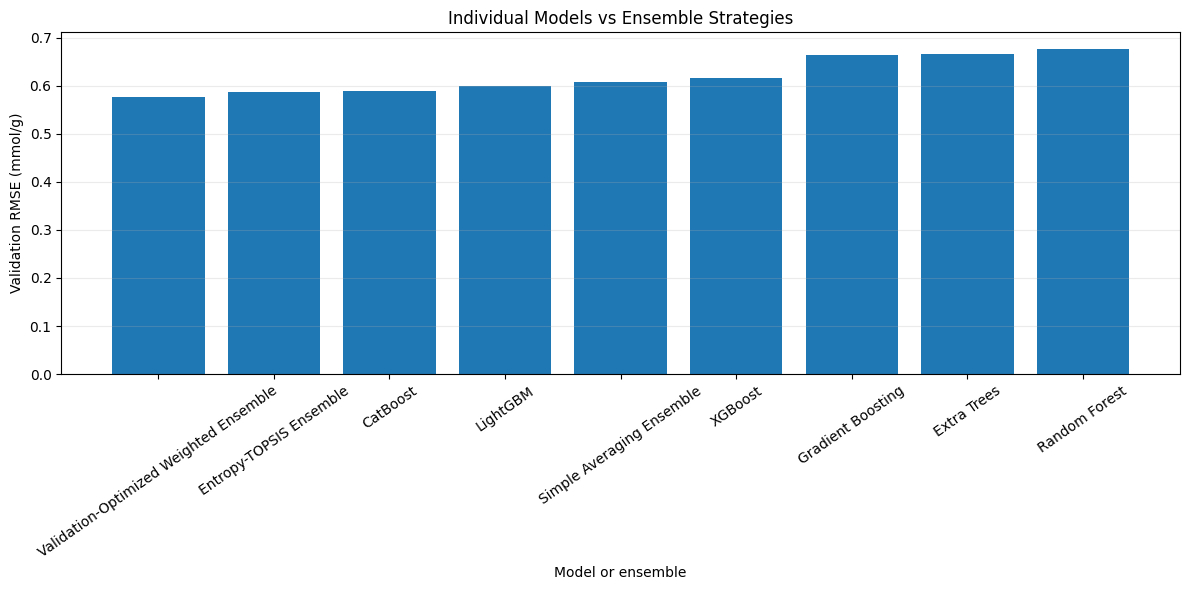

Saved: results/figures/ensemble_rmse_comparison.png


In [12]:

plot_df = ensemble_comparison_df.sort_values("RMSE")

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(plot_df["Model"], plot_df["RMSE"])

ax.set_title("Individual Models vs Ensemble Strategies")
ax.set_xlabel("Model or ensemble")
ax.set_ylabel("Validation RMSE (mmol/g)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

ensemble_plot_path = FIGURE_DIR / "ensemble_rmse_comparison.png"
fig.savefig(ensemble_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ensemble_plot_path.relative_to(PROJECT_ROOT))


In [13]:

best_validation_candidate = ensemble_comparison_df.iloc[0]

ensemble_summary = {
    "notebook": "07_ensemble_construction.ipynb",
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "validation_rows": int(len(val_df)),
    "test_rows_reserved": int(len(test_df)),
    "test_set_used": False,
    "strategies": [
        "Simple averaging",
        "Validation-optimized non-negative weights",
        "Entropy-TOPSIS weighting",
    ],
    "best_validation_candidate": str(best_validation_candidate["Model"]),
    "best_validation_rmse": float(best_validation_candidate["RMSE"]),
    "best_validation_mae": float(best_validation_candidate["MAE"]),
    "best_validation_r2": float(best_validation_candidate["R2"]),
    "caution": (
        "Validation-optimized weights and entropy-TOPSIS weights are "
        "validation-informed; their validation scores may be optimistic. "
        "Final generalization must be assessed on the untouched test set."
    ),
}

summary_path = RESULTS_DIR / "ensemble_summary.json"
with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(ensemble_summary, file, indent=4, ensure_ascii=False)

print("Ensemble construction completed.")
print("Best validation candidate:", ensemble_summary["best_validation_candidate"])
print(f"Validation RMSE: {ensemble_summary['best_validation_rmse']:.4f}")
print("Saved:", summary_path.relative_to(PROJECT_ROOT))


Ensemble construction completed.
Best validation candidate: Validation-Optimized Weighted Ensemble
Validation RMSE: 0.5759
Saved: results/ensemble_summary.json
